In [2]:
import sys
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("data/russian_demography.csv", sep=",", encoding="utf-8")

df.head()

,year,region,npg,birth_rate,death_rate,gdw,urbanization
0,1990,Republic of Adygea,1.9,14.2,12.3,84.66,52.42
1,1990,Altai Krai,1.8,12.9,11.1,80.24,58.07
2,1990,Amur Oblast,7.6,16.2,8.6,69.55,68.37
3,1990,Arkhangelsk Oblast,3.7,13.5,9.8,73.26,73.63
4,1990,Astrakhan Oblast,4.7,15.1,10.4,77.05,68.01


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2380 entries, 0 to 2379
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   year          2380 non-null   int64  
 1   region        2380 non-null   object 
 2   npg           2317 non-null   float64
 3   birth_rate    2317 non-null   float64
 4   death_rate    2315 non-null   float64
 5   gdw           2330 non-null   float64
 6   urbanization  2330 non-null   float64
dtypes: float64(5), int64(1), object(1)
memory usage: 130.3+ KB


In [4]:
df.describe()

,year,npg,birth_rate,death_rate,gdw,urbanization
count,2380.000000,2317.000000,2317.000000,2315.000000,2330.000000,2330.000000
mean,2003.500000,-2.344022,11.549245,13.901382,68.474013,69.148704
std,8.079445,6.064389,3.233035,3.499475,10.453587,13.349880
min,1990.000000,-15.900000,6.200000,3.200000,37.500000,23.630000
25%,1996.750000,-6.200000,9.300000,12.100000,61.380000,62.792500
50%,2003.500000,-3.100000,11.000000,14.100000,68.530000,69.575000
75%,2010.250000,0.700000,13.000000,16.100000,76.895000,77.620000
max,2017.000000,24.800000,29.900000,24.900000,97.530000,100.000000


In [5]:
print("Пропуски по столбцам:")
print(df.isna().sum())
print("\nПолных дубликатов в таблице:", df.duplicated().sum())
print("\nЧисло уникальных значений:")
print(df.nunique())


Пропуски по столбцам:
year             0
region           0
npg             63
birth_rate      63
death_rate      65
gdw             50
urbanization    50
dtype: int64

Полных дубликатов в таблице: 0

Число уникальных значений:
year              28
region            85
npg              307
birth_rate       175
death_rate       204
gdw             1701
urbanization    1310
dtype: int64


In [ ]:
mem_before = df.memory_usage(deep=True).sum()

df['year'] = df['year'].astype('uint16')
df['region'] = df['region'].astype('category')

mem_after = df.memory_usage(deep=True).sum()
print(f"Память до оптимизации: {mem_before / 1024:.2f} KB")
print(f"Память после оптимизации: {mem_after / 1024:.2f} KB")
print(f"Эффективность сжатия: {(1 - mem_after/mem_before)*100:.2f}%")


Память до оптимизации: 266.10 KB
Память после оптимизации: 107.64 KB
Эффективность сжатия: 59.55%


In [ ]:
df['calculated_npg_diff'] = df['birth_rate'] - df['death_rate']
print(df[['region', 'year', 'npg', 'calculated_npg_diff']].head())


               region  year  npg  calculated_npg_diff
0  Republic of Adygea  1990  1.9                  1.9
1          Altai Krai  1990  1.8                  1.8
2         Amur Oblast  1990  7.6                  7.6
3  Arkhangelsk Oblast  1990  3.7                  3.7
4    Astrakhan Oblast  1990  4.7                  4.7


In [ ]:
high_birth_urban = df.query("birth_rate > 15 and urbanization > 60")
print(f"Количество строк, удовлетворяющих фильтру: {len(high_birth_urban)}")
print(high_birth_urban.head())


Количество строк, удовлетворяющих фильтру: 110
    year                     region  npg  birth_rate  death_rate    gdw  \
2   1990                Amur Oblast  7.6        16.2         8.6  69.55   
4   1990           Astrakhan Oblast  4.7        15.1        10.4  77.05   
5   1990  Republic of Bashkortostan  6.5        16.2         9.7  80.53   
8   1990       Republic of Buryatia  9.2        18.3         9.1  79.47   
14  1990   Jewish Autonomous Oblast  8.2        17.8         9.6  76.11   

    urbanization  calculated_npg_diff  
2          68.37                  7.6  
4          68.01                  4.7  
5          64.22                  6.5  
8          62.16                  9.2  
14         65.01                  8.2  


In [ ]:
yearly_stats = df.groupby('year')[['birth_rate', 'death_rate']].mean()
print("--- Средние показатели по годам (фрагмент) ---")
print(yearly_stats.head())


region_stats = df.groupby('region')['npg'].agg(['min', 'max', 'mean', 'std'])
print("\n--- Статистика естественного прироста по регионам (фрагмент) ---")
print(region_stats.head())


--- Средние показатели по годам (фрагмент) ---
      birth_rate  death_rate
year                        
1990   14.354878   10.542683
1991   12.971951   10.775610
1992   11.479268   11.587805
1993   10.046914   13.833333
1994   10.228395   15.009877

--- Статистика естественного прироста по регионам (фрагмент) ---
                    min   max      mean       std
region                                           
Altai Krai         -6.4   1.8 -3.403571  2.208147
Altai Republic      0.3  10.9  4.853571  3.781973
Amur Oblast        -4.8   7.6 -1.550000  2.839601
Arkhangelsk Oblast -7.5   3.7 -3.600000  2.946812
Astrakhan Oblast   -4.4   4.7 -0.882143  2.780095


C:\Users\fedor\AppData\Local\Temp\ipykernel_13304\4092545207.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  region_stats = df.groupby('region')['npg'].agg(['min', 'max', 'mean', 'std'])


In [ ]:
corr_val = df['birth_rate'].corr(df['death_rate'])
print(f"Коэффициент корреляции Пирсона между рождаемостью и смертностью: {corr_val:.3f}")

q1 = df['birth_rate'].quantile(0.25)
q3 = df['birth_rate'].quantile(0.75)
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

outliers = df[(df['birth_rate'] < lower_bound) | (df['birth_rate'] > upper_bound)]
print(f"Границы нормы IQR: [{lower_bound:.2f}, {upper_bound:.2f}]")
print(f"Количество потенциальных выбросов: {len(outliers)}")
print("Примеры регионов-выбывающих за верхнюю границу:")
print(outliers[['region', 'year', 'birth_rate']].head())


Коэффициент корреляции Пирсона между рождаемостью и смертностью: -0.618
Границы нормы IQR: [3.75, 18.55]
Количество потенциальных выбросов: 80
Примеры регионов-выбывающих за верхнюю границу:
                       region  year  birth_rate
13       Republic of Dagestan  1990        26.1
19  Kabardino-Balkar Republic  1990        20.0
21       Republic of Kalmykia  1990        20.9
53             Altai Republic  1990        19.3
55              Tuva Republic  1990        26.3


C:\Users\fedor\AppData\Local\Temp\ipykernel_13304\875860863.py:16: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  top_regions = df.groupby('region')['npg'].mean().nlargest(5)


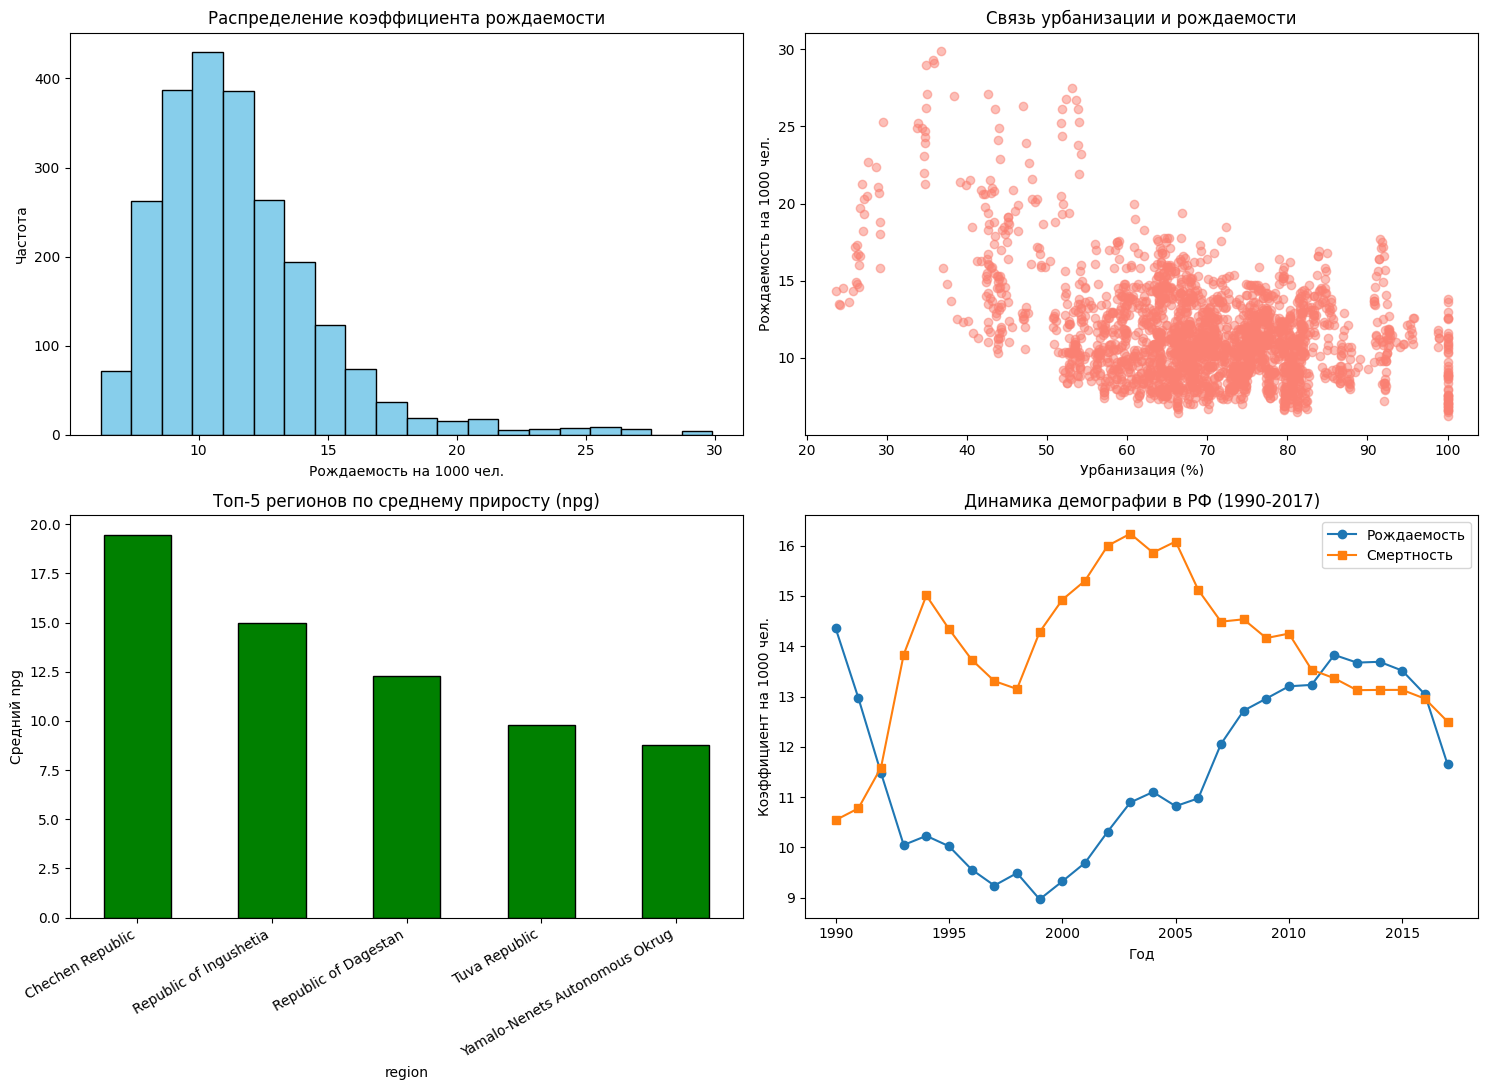

In [ ]:
fig, axs = plt.subplots(2, 2, figsize=(15, 11))


axs[0, 0].hist(df['birth_rate'].dropna(), bins=20, color='skyblue', edgecolor='black')
axs[0, 0].set_title('Распределение коэффициента рождаемости')
axs[0, 0].set_xlabel('Рождаемость на 1000 чел.')
axs[0, 0].set_ylabel('Частота')


axs[0, 1].scatter(df['urbanization'], df['birth_rate'], alpha=0.5, color='salmon')
axs[0, 1].set_title('Связь урбанизации и рождаемости')
axs[0, 1].set_xlabel('Урбанизация (%)')
axs[0, 1].set_ylabel('Рождаемость на 1000 чел.')


top_regions = df.groupby('region')['npg'].mean().nlargest(5)
top_regions.plot(kind='bar', ax=axs[1, 0], color='green', edgecolor='black')
axs[1, 0].set_title('Топ-5 регионов по среднему приросту (npg)')
axs[1, 0].set_ylabel('Средний npg')
axs[1, 0].set_xticklabels(top_regions.index, rotation=30, ha='right')


yearly_trends = df.groupby('year')[['birth_rate', 'death_rate']].mean()
axs[1, 1].plot(yearly_trends.index, yearly_trends['birth_rate'], label='Рождаемость', marker='o')
axs[1, 1].plot(yearly_trends.index, yearly_trends['death_rate'], label='Смертность', marker='s')
axs[1, 1].set_title('Динамика демографии в РФ (1990-2017)')
axs[1, 1].set_xlabel('Год')
axs[1, 1].set_ylabel('Коэффициент на 1000 чел.')
axs[1, 1].legend()

plt.tight_layout()
plt.show()


In [ ]:
import os


df_to_save = df.copy()


if 'region' in df_to_save.columns:
    df_to_save['region'] = df_to_save['region'].astype(str)


df_to_save.to_csv("clean_demography.csv", index=False)


df_to_save.to_parquet("clean_demography.parquet", index=False, engine='pyarrow')


size_csv = os.path.getsize("clean_demography.csv") / 1024
size_parquet = os.path.getsize("clean_demography.parquet") / 1024

print(f"Размер CSV-файла: {size_csv:.2f} KB")
print(f"Размер Parquet-файла: {size_parquet:.2f} KB")


df_parquet = pd.read_parquet("clean_demography.parquet", engine='pyarrow')
print(f"Повторное чтение прошло успешно. Форма считанной таблицы: {df_parquet.shape}")


Размер CSV-файла: 145.67 KB
Размер Parquet-файла: 41.14 KB
Повторное чтение прошло успешно. Форма считанной таблицы: (2380, 8)
